In [1]:
import tensorflow

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout)

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
#load dataset with supervised labels

(ds_train_full, ds_test),ds_info = tfds.load(
    'rock_paper_scissors',
    split=['train','test'],
    as_supervised=True,
    with_info=True,

)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

In [5]:
#reserve Validation split from training

val_size=int(0.2*ds_info.splits['train'].num_examples)
ds_train=ds_train_full.skip(val_size)
ds_val=ds_train_full.take(val_size)

class_names=ds_info.features['label'].names
print("Classes: ",class_names)

Classes:  ['rock', 'paper', 'scissors']


In [6]:
IMG_SIZE =150
BATCH_SIZE=32
NUM_CLASSES =3

def preprocess(image, label):
   image= tf.image.resize(image,(IMG_SIZE,IMG_SIZE))/255.0
   label = tf.one_hot(label,NUM_CLASSES)
   return image,label

train_aug=ds_train.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_data=ds_val.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_data = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

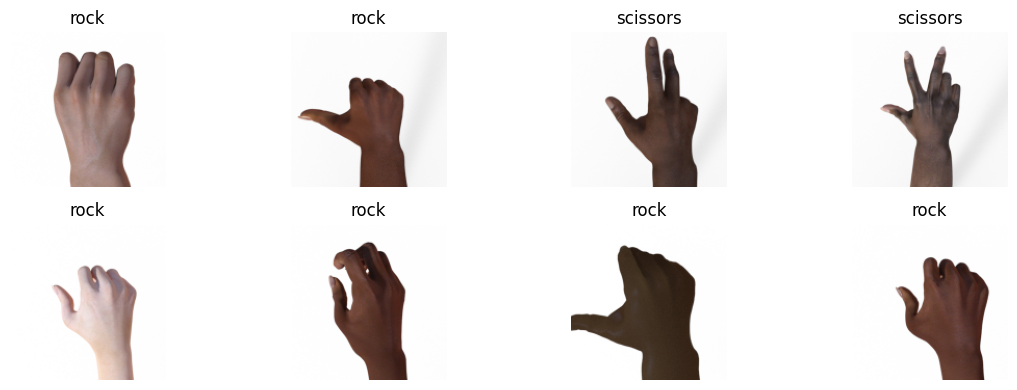

In [7]:
for images,labels in train_aug.take(1):
  plt.figure(figsize=(12,4))
  for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i].numpy())
    plt.title(class_names[tf.argmax(labels[i]).numpy()])
    plt.axis('off')
  plt.tight_layout()
  plt.show()

In [8]:
inputs = Input(shape=(IMG_SIZE,IMG_SIZE,3))

x=Conv2D(32,(3,3),activation='relu',name='conv1')(inputs)
x=MaxPooling2D((2,2),name='pool1')(x)

x=Conv2D(64,(3,3),activation='relu',name='conv2')(x)
x=MaxPooling2D((2,2),name='pool2')(x)

x=Conv2D(128,(3,3),activation='relu',name='conv3')(x)
x=MaxPooling2D((2,2),name='pool3')(x)

x=Flatten(name='flatten')(x)
x=Dense(128,activation='relu',name='dense1')(x)
x=Dropout(0.5)(x)

outputs=Dense( NUM_CLASSES, activation='softmax',name='output')(x)

In [9]:
model =Model(inputs,outputs)


In [10]:
model.compile(optimizer= 'adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
history= model.fit(
    train_aug,
    epochs=15,
    validation_data=val_data,
    callbacks=[EarlyStopping(patience=3,restore_best_weights=True)],
    verbose=1
)

Epoch 1/15
23/63 ━━━━━━━━━━━━━━━━━━━━ 1:01 2s/step - accuracy: 0.4460 - loss: 1.5453

In [24]:
#evaluate
loss,acc= model.evaluate(test_data,verbose=0)
print(f"Test accuracy:,{acc:.4f}")

Test accuracy:,0.8575


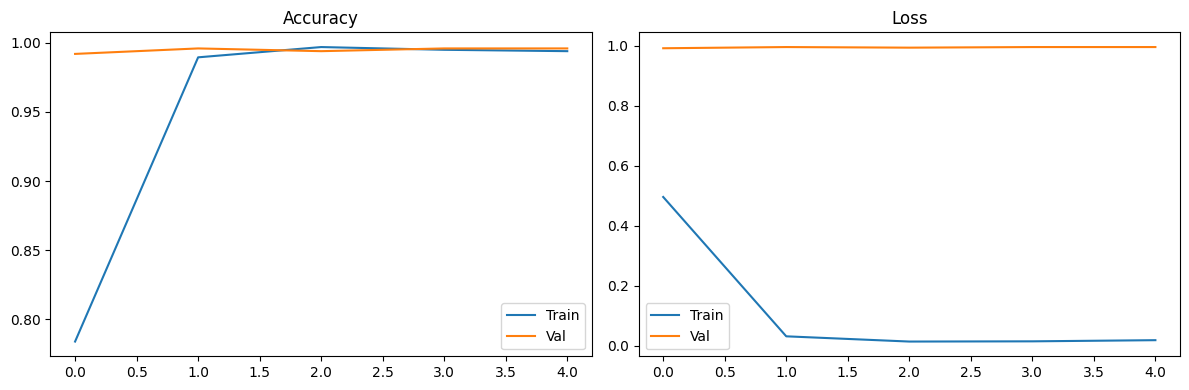

In [31]:
#plot
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],label='Train')
plt.plot(history.history['val_accuracy'],label='Val')

plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'],label='Train')
plt.plot(history.history['val_accuracy'],label='Val')
plt.title('Loss')

plt.legend()
plt.tight_layout()
plt.show()


In [2]:
#pick a test image

for img_batch in test_data.take(1):
  img,labels=img_batch
  break

#create intermediate model for 3 conv layer

intermediate_model = Model(inputs=model.input,outputs=[
    model.get_layer('conv1').output,
    model.get_layer('conv2').output,
    model.get_layer('conv3').output,
])

#predict feature apps
feature_maps= intermediate_model.predict(img.reshape(1,IMG_SIZE, IMG_SIZE,3))
#plot orignal
plt.figure(figsize=(16,4))
#subplot
plt.subplot(1,4,1)
plt.imshow(img)
plt.title('Orignal image')
plt.axis('off')

#plot feature map 0 from each conv layer

for i, fmap in enumerate(feature_maps):
  plt.subplot(1,4,i+2)
  plt.imshow(fmap[0,:,:,0],cmap='viridis')
  plt.title(f"conv{i+1}map 0")
  plt.axis('off')
  plt.tight_layout()
  plt.show()

NameError: name 'test_data' is not defined